# Comparaison SGD / RMSProp / Adam sur un MLP (MNIST)

Cette partie compare les performances de SGD, RMSProp et Adam pour l'entraînement d'un MLP avec 2 couches cachées sur MNIST.  
Pour chaque méthode, le learning rate est d'abord choisi sur un jeu de validation, puis les résultats finaux sont mesurés sur le jeu de test, selon quatre critères : vitesse de convergence, stabilité, qualité finale et sensibilité au learning rate.

In [2]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

from training_toolbox import Trainer, accuracy

**I) Paramètres**

In [ ]:
BATCH_SIZE = 128
OPTIMISEURS = {
    "SGD": torch.optim.SGD,
    "RMSProp": torch.optim.RMSprop,
    "Adam": torch.optim.Adam,
}
GRILLE_LR = [1e-10, 1e-8, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0]
EPOCHS_LR = 5      # passages complets sur le jeu d'entraînement
N_SEEDS_LR = 2     # nbr de répétitions en remplaçant les paramètres de départ 

**II) Données**

Données de validation = les 10 000 dernières images du train (le test n'est pas utilisé pour choisir le lr).

In [10]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),
    transforms.Lambda(lambda x: x.view(-1)),
])

mnist_train = datasets.MNIST(root="./data", train=True, download=True, transform=transform)

train_loader = DataLoader(Subset(mnist_train, range(50000)), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(Subset(mnist_train, range(50000, 60000)), batch_size=1000, shuffle=False)

**III) Le MLP**

In [11]:
class MulticlassMLP(nn.Module):
    def __init__(self, n_features=784, hidden_1=128, hidden_2=64, n_classes=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_features, hidden_1),
            nn.ReLU(),
            nn.Linear(hidden_1, hidden_2),
            nn.ReLU(),
            nn.Linear(hidden_2, n_classes),
        )

    def forward(self, x):
        return self.net(x)

**IV) Entraînement avec un optimiseur passé en variable**

In [12]:
def run(optimizer_cls, lr, epochs, seed, train_loader=train_loader, val_loader=val_loader):
    torch.manual_seed(seed)
    model = MulticlassMLP()
    optimizer = optimizer_cls(model.parameters(), lr=lr)
    trainer = Trainer(model, optimizer, nn.CrossEntropyLoss(), metrics={"acc": accuracy})
    return trainer.fit(train_loader, val_loader, epochs=epochs)

**V) Expérience : sensibilité au learning rate**

In [13]:
acc = {nom: [] for nom in OPTIMISEURS}

for nom, opt_cls in OPTIMISEURS.items():
    for lr in GRILLE_LR:
        a = np.mean([run(opt_cls, lr, EPOCHS_LR, seed)["val_acc"][-1] for seed in range(N_SEEDS_LR)])
        acc[nom].append(a)
        print(f"{nom:8s} lr={lr:<8g} -> précision validation = {a:.4f}")

best_lr = {nom: GRILLE_LR[int(np.argmax(acc[nom]))] for nom in OPTIMISEURS}
print("Meilleur lr :", best_lr)

Epoch 1/5 - train_loss: 2.3068 - train_acc: 0.1067 - val_loss: 2.3060 - val_acc: 0.1068
Epoch 2/5 - train_loss: 2.3068 - train_acc: 0.1067 - val_loss: 2.3060 - val_acc: 0.1068
Epoch 3/5 - train_loss: 2.3068 - train_acc: 0.1067 - val_loss: 2.3060 - val_acc: 0.1068
Epoch 4/5 - train_loss: 2.3068 - train_acc: 0.1067 - val_loss: 2.3060 - val_acc: 0.1068
Epoch 5/5 - train_loss: 2.3068 - train_acc: 0.1067 - val_loss: 2.3060 - val_acc: 0.1068
Epoch 1/5 - train_loss: 2.3012 - train_acc: 0.1092 - val_loss: 2.3020 - val_acc: 0.1081
Epoch 2/5 - train_loss: 2.3012 - train_acc: 0.1092 - val_loss: 2.3020 - val_acc: 0.1081
Epoch 3/5 - train_loss: 2.3012 - train_acc: 0.1092 - val_loss: 2.3020 - val_acc: 0.1081
Epoch 4/5 - train_loss: 2.3012 - train_acc: 0.1092 - val_loss: 2.3020 - val_acc: 0.1081
Epoch 5/5 - train_loss: 2.3012 - train_acc: 0.1092 - val_loss: 2.3020 - val_acc: 0.1081
SGD      lr=1e-10    -> précision validation = 0.1075
Epoch 1/5 - train_loss: 2.3068 - train_acc: 0.1067 - val_loss: 2.3

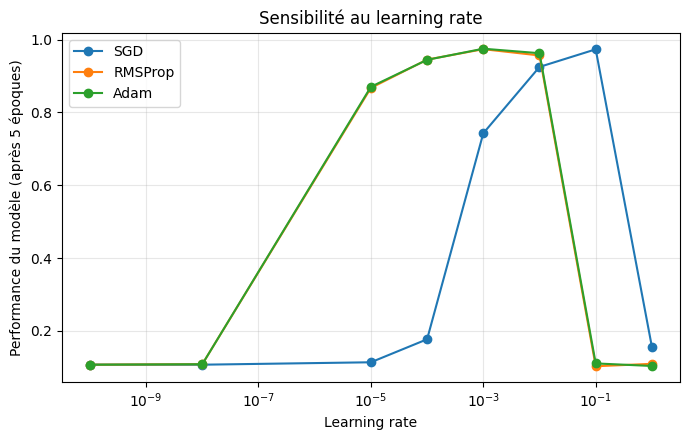

In [14]:
plt.figure(figsize=(7, 4.5))
for nom in OPTIMISEURS:
    plt.plot(GRILLE_LR, acc[nom], marker="o", label=nom)
plt.xscale("log")
plt.xlabel("Learning rate")
plt.ylabel(f"Performance du modèle (après {EPOCHS_LR} époques)") # métrique utilisée : accuracy
plt.title("Sensibilité au learning rate")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("exp1_sensibilite_lr.png", dpi=150)
plt.show()

Ce graphique montre le niveau de performance du modèle (métrique : accuracy) après 5 époques en fonction du learning rate (échelle logarithmique). 

Il est important de choisir une valeur pour le learning rate adaptée, afin d'avoir un bon compromis entre **vitesse de convergence** (un learning rate trop petit rend l’apprentissage très lent, voire insuffisant en un nombre d’époques donné) et **stabilité** (un learning rate trop grand provoque des oscillations, voire une divergence).
  
Pour des learning rates très faibles (1e-10, 1e-8), la performance du modèle est de 0,10, ce qui correspond au hasard puisqu'on a 10 classes en sortie.
Avec ces valeurs pour le pas, aucune méthode n’apprend car les poids sont trop peu modifiés en 5 époques.  

On remarque que SGD reste au niveau du hasard jusqu’à 1e-5, alors que RMSProp et Adam atteignent déjà ~0,87 : leur pas de mise à jour est normalisé par l’amplitude du gradient, ce qui les rend moins pénalisés par de petits learning rates.  

Les meilleurs résultats sont obtenus pour des valeurs très différentes selon la méthode : lr = 1e-3 pour RMSProp et Adam (~0,975), lr = 1e-1 pour SGD (~0,97), soit un facteur 100 d’écart.   
  
Au-delà, les performances s’effondrent : Adam et RMSProp divergent dès 1e-1, SGD à 1,0. Le learning rate est trop grand pour que l’optimiseur converge : les mises à jour dépassent le minimum et le modèle n’apprend plus (précision au niveau du hasard).

Le learning rate n’a pas la même signification selon la méthode : SGD multiplie le gradient par le lr (et les gradients sont petits, d’où un lr optimal élevé, ~0,1), alors que RMSProp et Adam normalisent le gradient par son amplitude, ce qui fait que le pas est de l’ordre du lr lui-même (d’où un lr optimal bien plus petit, ~1e-3).

Les valeurs optimales ne sont donc pas comparables entre méthodes : ce qui compte, c’est la performance obtenue avec le meilleur lr de chacune.

Epoch 1/10 - train_loss: 0.4093 - train_acc: 0.8792 - val_loss: 0.2078 - val_acc: 0.9374
Epoch 2/10 - train_loss: 0.1558 - train_acc: 0.9540 - val_loss: 0.1250 - val_acc: 0.9623
Epoch 3/10 - train_loss: 0.1082 - train_acc: 0.9671 - val_loss: 0.0976 - val_acc: 0.9697
Epoch 4/10 - train_loss: 0.0825 - train_acc: 0.9751 - val_loss: 0.0803 - val_acc: 0.9754
Epoch 5/10 - train_loss: 0.0645 - train_acc: 0.9805 - val_loss: 0.0815 - val_acc: 0.9757
Epoch 6/10 - train_loss: 0.0523 - train_acc: 0.9842 - val_loss: 0.0796 - val_acc: 0.9745
Epoch 7/10 - train_loss: 0.0427 - train_acc: 0.9879 - val_loss: 0.0671 - val_acc: 0.9786
Epoch 8/10 - train_loss: 0.0350 - train_acc: 0.9894 - val_loss: 0.0696 - val_acc: 0.9789
Epoch 9/10 - train_loss: 0.0292 - train_acc: 0.9915 - val_loss: 0.0802 - val_acc: 0.9750
Epoch 10/10 - train_loss: 0.0243 - train_acc: 0.9929 - val_loss: 0.0692 - val_acc: 0.9805
Epoch 1/10 - train_loss: 0.3963 - train_acc: 0.8818 - val_loss: 0.1939 - val_acc: 0.9419
Epoch 2/10 - train_l

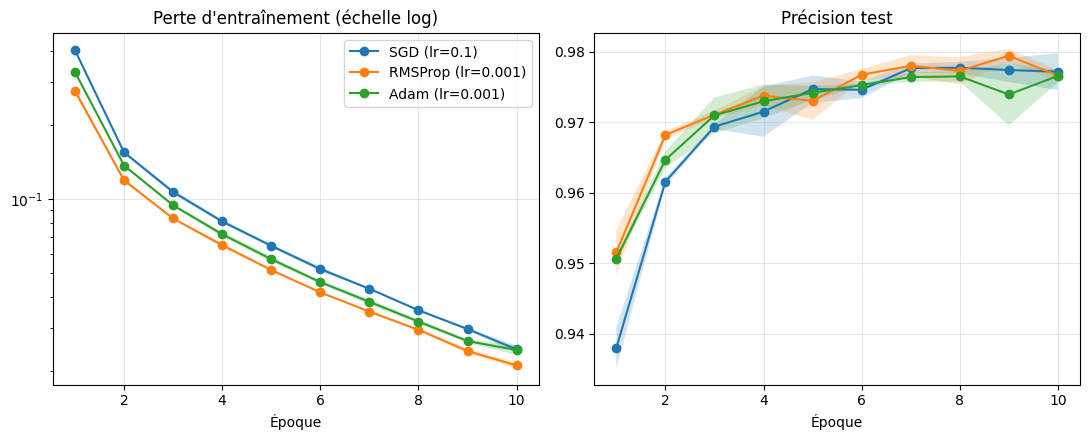

In [ ]:
EPOCHS = 10
N_SEEDS = 3

# Entraînement sur les 60 000 images, évaluation sur le test (10 000)
mnist_test = datasets.MNIST(root="./data", train=False, download=True, transform=transform)
full_train_loader = DataLoader(mnist_train, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(mnist_test, batch_size=1000, shuffle=False)

results = {}
for nom, opt_cls in OPTIMISEURS.items():
    runs = [run(opt_cls, best_lr[nom], EPOCHS, seed, full_train_loader, test_loader)
            for seed in range(N_SEEDS)]
    results[nom] = {k: np.array([r[k] for r in runs]) for k in ("train_loss", "val_acc")}
    r = results[nom]
    print(f"{nom:8s} lr={best_lr[nom]:<6g} | précision test finale = "
          f"{r['val_acc'][:, -1].mean():.4f} +/- {r['val_acc'][:, -1].std():.4f}")

epochs = np.arange(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
panneaux = [("train_loss", "Perte d'entraînement (échelle log)"),
            ("val_acc", "Performance du modèle")]
for ax, (key, titre) in zip(axes, panneaux):
    for nom in OPTIMISEURS:
        m, s = results[nom][key].mean(0), results[nom][key].std(0)
        ax.plot(epochs, m, marker="o", label=f"{nom} (lr={best_lr[nom]:g})")
        ax.fill_between(epochs, m - s, m + s, alpha=0.2)
    ax.set_title(titre)
    ax.set_xlabel("Époque")
    ax.grid(alpha=0.3)
axes[0].set_yscale("log")
axes[0].legend()
plt.tight_layout()
plt.savefig("exp2_convergence.png", dpi=150)
plt.show()

La **perte d’entraînement** est mesurée uniquement sur les données d’entraînement. Elle reflète à la fois les erreurs de classification du modèle et le degré de confiance avec lequel il prédit. Les optimiseurs ont pour but de minimiser cette perte en ajustant les poids du réseau.

Ici, la perte diminue nettement au fil des époques pour les trois méthodes, sans oscillation ni divergence. RMSProp reste légèrement en dessous des deux autres sur toute la durée, Adam est juste derrière, et SGD est le plus lent au départ. L’écart se réduit avec les époques : à l’époque 10, SGD et Adam sont presque confondus. Les différences entre les trois méthodes sont donc faibles.

Les trois optimiseurs parviennent ainsi à minimiser efficacement la perte sur les données d’entraînement. Reste à vérifier, avec la précision de test, que cet apprentissage se généralise à des données nouvelles.

La **précision de test** est le critère de performance du modèle. Ici, on a utilisé l'accuracy. Il permet de connaître la proportion d’images de test correctement classées. Elle est calculée sur des données que le réseau n’a pas utilisées pour apprendre, ce qui permet de vérifier sa capacité à généraliser.  
    
À l’époque 1, RMSProp et Adam sont à ~0,95 contre ~0,94 pour SGD. SGD les rattrape vers l’époque 3-4.  
À la fin, les trois sont autour de 0,977. Les écarts entre méthodes sont du même ordre que les bandes d’erreur (Adam : 0,9766 ± 0,0009), donc on ne peut pas désigner un gagnant sur la qualité finale.  
  
Les bandes d’Adam et de RMSProp sont un peu plus larges sur les dernières époques, avec un creux visible pour Adam à l’époque 9. Avec seulement 3 seeds, je lirais ça comme du bruit plutôt que comme de l’instabilité.

Ces 2 graphiques nous renseignent également sur la question d'un éventuel **sur-apprentissage** du modèle.  
Effectivement, on remarque que la perte d’entraînement continue de baisser, mais la précision test stagne dès l’époque 6-7. On peut donc conclure que continuer l'entraînement n'apporterait plus rien, voire commencerait à faire sur-apprendre le modèle.

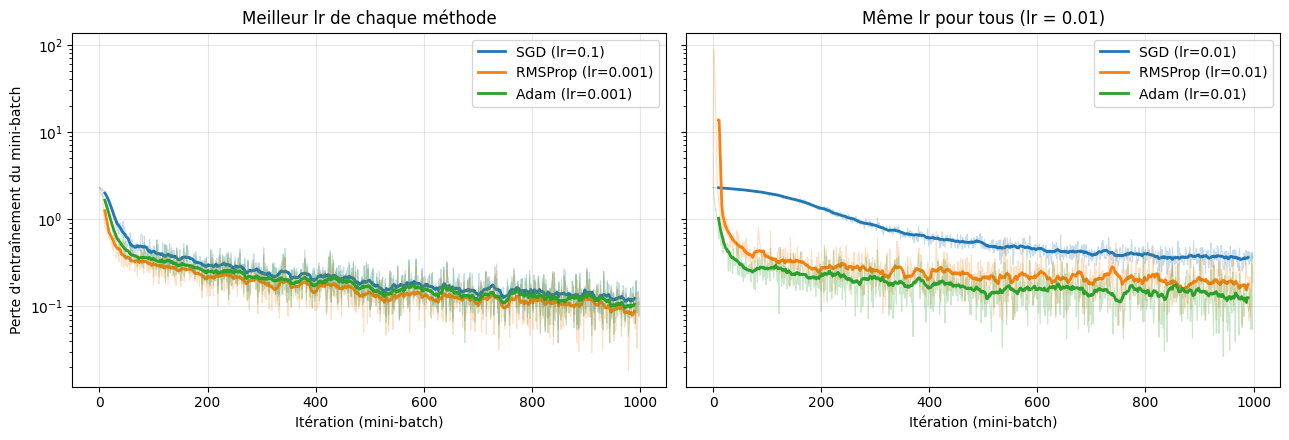

In [ ]:
def loss_par_batch(optimizer_cls, lr, n_iter=1000, seed=0):
    torch.manual_seed(seed)
    model = MulticlassMLP()
    optimizer = optimizer_cls(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()
    pertes = []
    model.train()
    while len(pertes) < n_iter:
        for xb, yb in full_train_loader:
            loss = loss_fn(model(xb), yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            pertes.append(loss.item())
            if len(pertes) == n_iter:
                break
    return np.array(pertes)

def moyenne_mobile(x, fenetre=20):
    return np.convolve(x, np.ones(fenetre) / fenetre, mode="valid")

LR_COMMUN = 1e-2   # même lr pour les 3 méthodes : comparaison à armes égales
configs = [("Meilleur lr de chaque méthode", lambda nom: best_lr[nom]),
           (f"Même lr pour tous (lr = {LR_COMMUN:g})", lambda nom: LR_COMMUN)]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, (titre, get_lr) in zip(axes, configs):
    for nom, opt_cls in OPTIMISEURS.items():
        lr = get_lr(nom)
        p = loss_par_batch(opt_cls, lr)
        l, = ax.plot(p, alpha=0.25, linewidth=0.8)                      # perte brute par batch
        ax.plot(np.arange(len(moyenne_mobile(p))) + 10, moyenne_mobile(p),
                color=l.get_color(), linewidth=2, label=f"{nom} (lr={lr:g})")  # tendance lissée
    ax.set_title(titre)
    ax.set_xlabel("Itération (mini-batch)")
    ax.set_yscale("log")
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_ylabel("Perte d'entraînement du mini-batch")
plt.tight_layout()
plt.savefig("exp3_oscillations.png", dpi=150)
plt.show()

**Stabilité (perte par mini-batch)**. Le graphique montre la perte de chaque mini-batch pendant les 1 000 premières itérations (courbes pâles : perte brute ; courbes épaisses : tendance lissée).

**À gauche, au meilleur learning rate de chaque méthode** : les trois courbes sont très proches. La perte chute rapidement sur les ~100 premières itérations, puis décroît lentement. Dans les trois cas, la perte brute fluctue fortement d'un mini-batch à l'autre, sans qu'une méthode se distingue nettement des autres par l'amplitude de ces fluctuations.

**À droite, avec le même learning rate (0,01) pour les trois méthodes** : les écarts sont plus marqués. SGD descend nettement plus lentement et reste à une perte plus élevée au bout de 1 000 itérations. Les fluctuations d'un mini-batch à l'autre restent présentes pour les trois méthodes.

Sur ce MLP, il n'y a donc pas de différence nette de stabilité entre les trois méthodes au meilleur learning rate. Avec un learning rate commun, la différence se voit surtout sur la vitesse de descente.

  
    

**Conclusion** : Sur ce MLP entraîné sur MNIST, SGD, RMSProp et Adam atteignent la même précision test (≈ 97,7 %) lorsque le learning rate est bien réglé : le choix de l'optimiseur ne change donc pas la qualité finale. Les méthodes adaptatives se distinguent par une convergence plus rapide en début d'entraînement et par une meilleure tolérance aux petits learning rates, leur lr optimal étant environ 100 fois plus petit que celui de SGD, mais nous n'observons pas de différence nette de stabilité. L'intérêt d'Adam et RMSProp est donc surtout pratique (moins de réglage et un démarrage plus rapide), tandis qu'un SGD bien réglé reste tout à fait compétitif sur ce problème simple.